In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [3]:
plt.rcParams.update(
    {
        "text.usetex": True,
        "font.size": 16
    }
)

In [4]:
fname_results = "../experiment_results.csv"
df_all = pd.read_csv(fname_results)
df_all.head()

,id,seq,dist_azo,activity_37,activity_60,wt_id,region,sb_score,dca_energy
0,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_...,GUGCAUUCCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,28,-2.982426,-3.578521,2.0,lowDCA_lowSB,4.724404,76.87851
1,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_696,GUGCAUUCCGUCGGGAAACCACCGAAUGGAUGUUGUCAAAUUCGGU...,25,-2.646676,-3.208042,2.0,lowDCA_lowSB,5.871308,79.71062
2,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_910,GUGCAUUCCGCCGGGAAACCACUGAAUGGCUGUUGUCAAAUUCGGU...,27,-0.592556,-2.084677,2.0,lowDCA_lowSB,9.615535,76.88864
3,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_545,GUGCAUUCCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,29,-2.463253,-3.154773,2.0,lowDCA_lowSB,4.109425,74.89435
4,MARTIN_wt_2_mut_lowDCA_lowSB_beta1.25_sb-3.00_...,GUGCAUUUCGUCGGGAAACCACCGAAUGGCUGUUGUCAAAUUCGGU...,25,-1.349940,-2.098292,2.0,lowDCA_lowSB,9.580202,75.90297


In [5]:
df_overlap = df_all[df_all["region"] == "overlap"]
print(df_overlap.shape)

mask_overlap_60 = df_overlap["activity_60"] != -5
df_overlap_masked_60 = df_overlap[mask_overlap_60]
print(df_overlap_masked_60.shape)

mask_overlap_37 = df_overlap["activity_37"] != -5
df_overlap_masked_37 = df_overlap[mask_overlap_37]
print(df_overlap_masked_37.shape)

mean_activity_overlap_60 = df_overlap_masked_60["activity_60"].mean()
mean_activity_overlap_37 = df_overlap_masked_37["activity_37"].mean()
print(f"Mean activity in overlap region (60): {mean_activity_overlap_60:.2f}")
print(f"Mean activity in overlap region (37): {mean_activity_overlap_37:.2f}")

(355, 9)
(348, 9)
(349, 9)
Mean activity in overlap region (60): -0.19
Mean activity in overlap region (37): 0.03


In [6]:
mask_detected_37 = df_all["activity_37"] != -5
mask_detected_60 = df_all["activity_60"] != -5

df_all.loc[mask_detected_37, "activity_37"] -= mean_activity_overlap_37
df_all.loc[mask_detected_60, "activity_60"] -= mean_activity_overlap_60

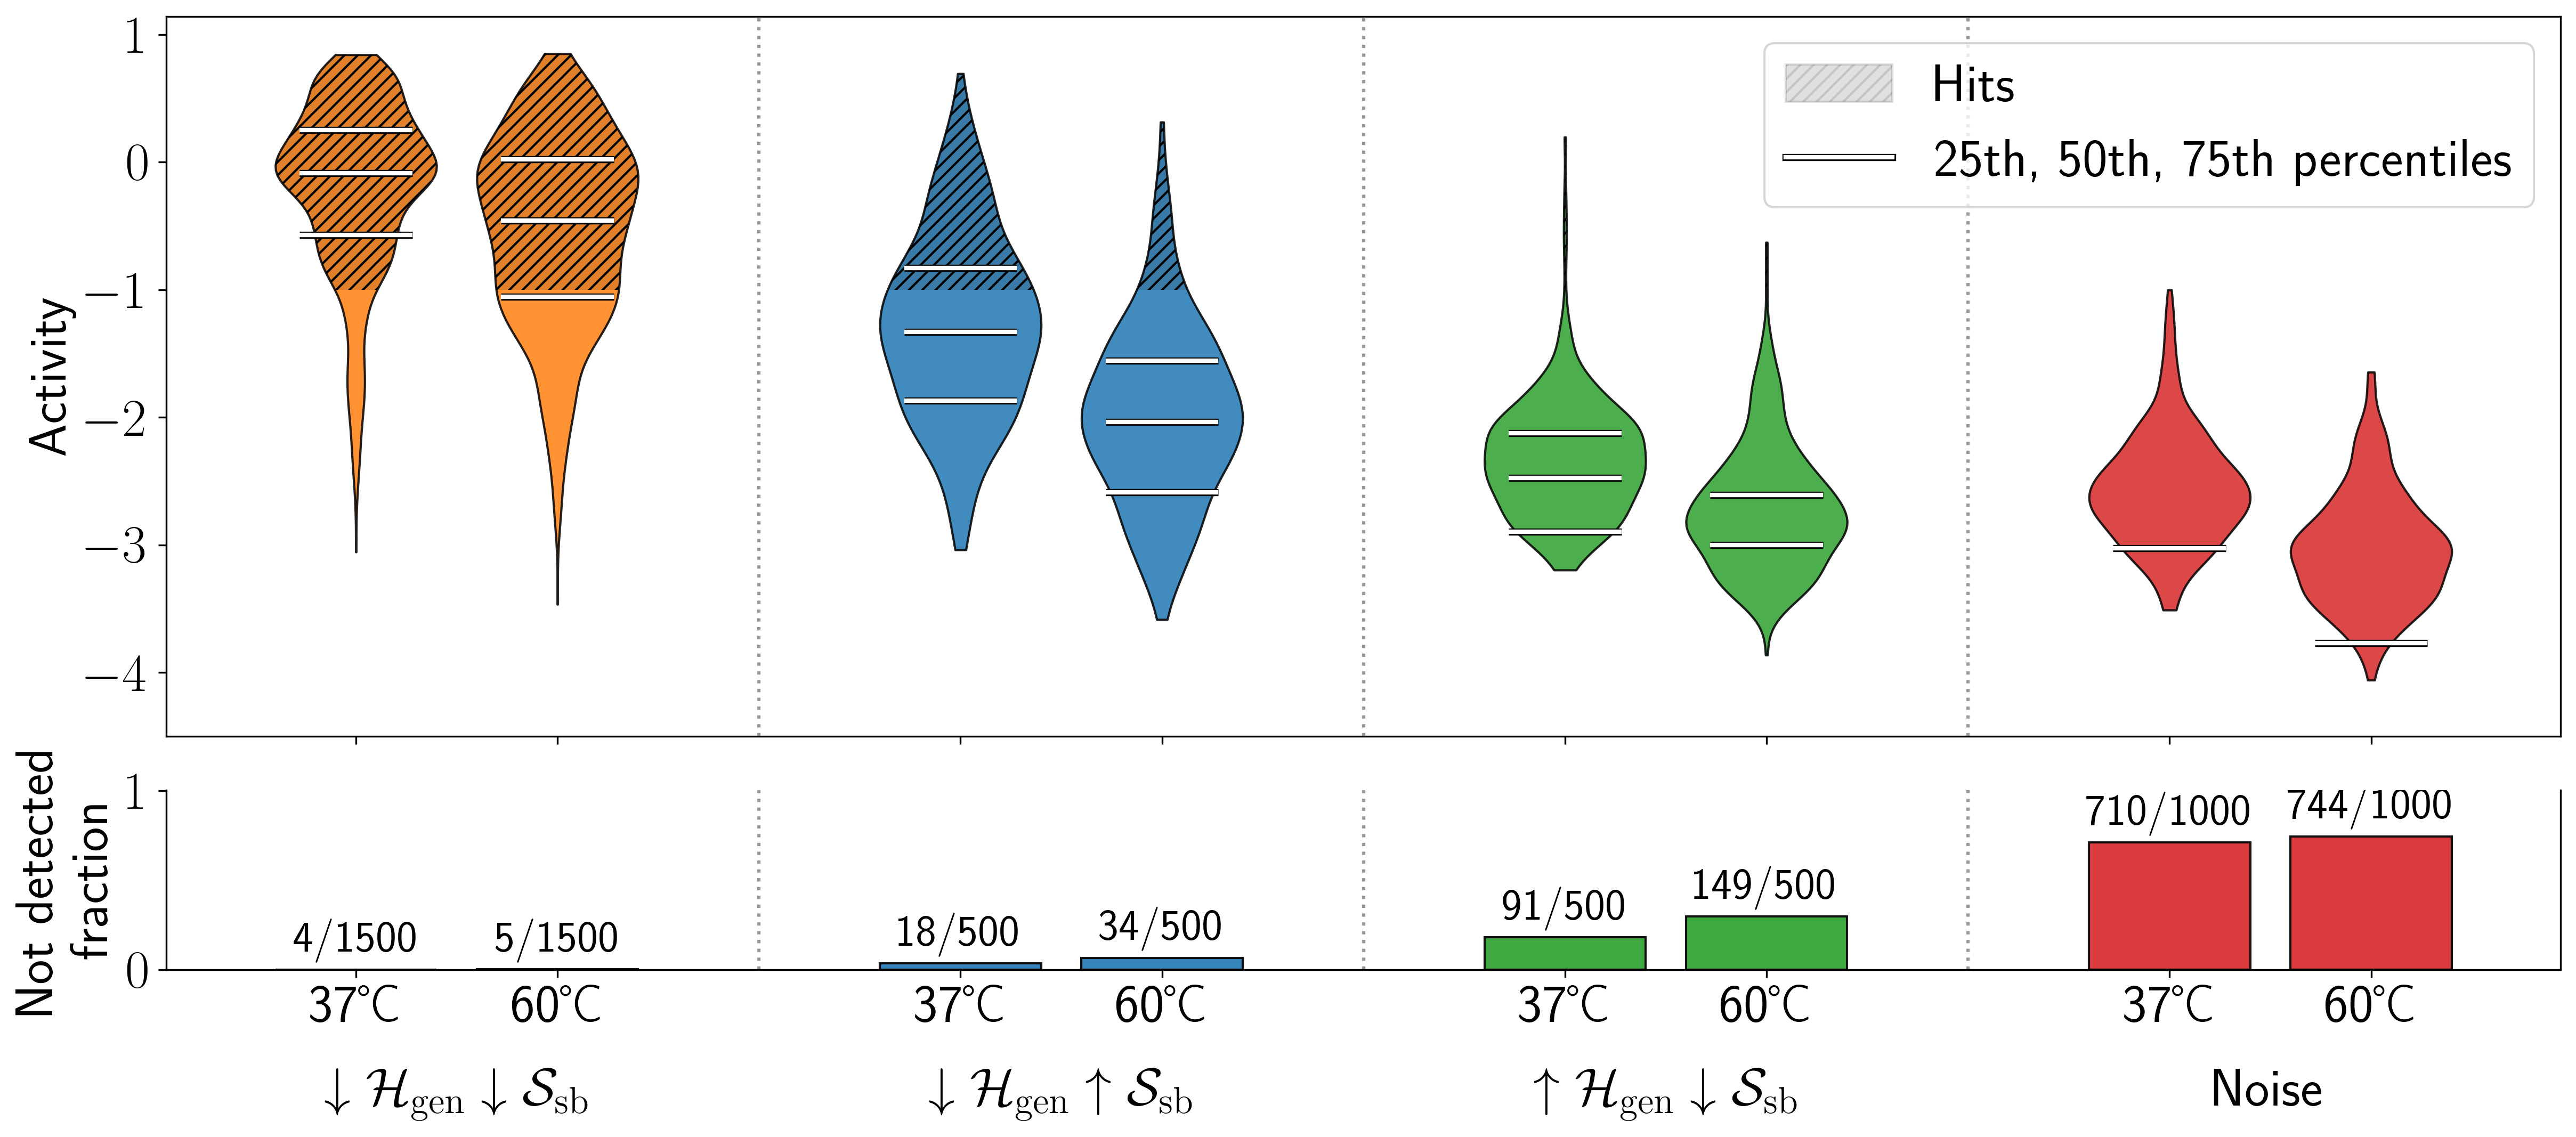

In [7]:
import matplotlib.patheffects as pe
from matplotlib.patches import Patch

regions = ["lowDCA_highSB", "lowDCA_lowSB", "highDCA_highSB", "control"]

# Global font size for all plot text except bar annotations.
global_font_size = 24
plt.rcParams.update({"font.size": global_font_size})

# Keep bar annotations independent from global font size.
bar_annotation_font_size = 20

# Edit this dictionary to customize x-axis labels.
x_label_map = {
    "37": "37℃",
    "60": "60℃",
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_\mathrm{gen} \downarrow \mathcal{S}_\mathrm{sb}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_\mathrm{gen} \uparrow \mathcal{S}_\mathrm{sb}$",
    "highDCA_highSB": r"$\uparrow \mathcal{H}_\mathrm{gen} \downarrow \mathcal{S}_\mathrm{sb}$",
    "control": "Noise",
}

tab10 = sns.color_palette("tab10")
region_colors = [tab10[1], tab10[0], tab10[2], tab10[3]]  # orange, blue, green, red
palette = dict(zip(regions, region_colors))

# Fixed lower limit for hits shading (same for 37 and 60).
hits_bottom = -1.0

fig, (ax_top, ax_bottom) = plt.subplots(
    2,
    1,
    figsize=(16, 7),
    sharex=True,
    constrained_layout=True,
    gridspec_kw={"height_ratios": [4, 1], "hspace": 0.05},
    dpi=300,
)

positions = []
labels = []
pair_centers = []
current_pos = 0
violin_metadata = []
missing_fracs = []
bar_colors = []
bar_texts = []

for region in regions:
    region_df = df_all[df_all["region"] == region]

    left_pos = current_pos
    right_pos = current_pos + 1
    pair_centers.append((left_pos + right_pos) / 2)

    for pos, col, short_label in [(left_pos, "activity_37", "37"), (right_pos, "activity_60", "60")]:
        # Violin excludes undetected values (-5).
        violin_values = region_df.loc[region_df[col] != -5, col].dropna().values
        if len(violin_values) > 0:
            vp = ax_top.violinplot(
                dataset=[violin_values],
                positions=[pos],
                widths=0.8,
                showmeans=False,
                showextrema=False,
                showmedians=False,
            )

            for body in vp["bodies"]:
                body.set_facecolor(palette[region])
                body.set_edgecolor("black")
                body.set_alpha(0.85)
                violin_metadata.append((body, pos))

        # Percentiles include all values, including -5.
        pct_values = region_df[col].dropna().values
        if len(pct_values) > 0:
            q25, q50, q75 = np.percentile(pct_values, [25, 50, 75])
            pct_lines = ax_top.hlines(
                [q25, q50, q75],
                pos - 0.28,
                pos + 0.28,
                colors="white",
                linestyles="-",
                linewidth=2.0,
                zorder=6,
            )
            pct_lines.set_path_effects([
                pe.Stroke(linewidth=3.2, foreground="black"),
                pe.Normal(),
            ])

        # Fraction of undetected values (-5) for the barplot.
        total_n = region_df[col].notna().sum()
        n_minus5 = (region_df[col] == -5).sum()
        frac_minus5 = n_minus5 / total_n if total_n > 0 else np.nan
        missing_fracs.append(frac_minus5)
        bar_texts.append(f"{n_minus5}/{total_n}")
        bar_colors.append(palette[region])

        positions.append(pos)
        labels.append(x_label_map.get(short_label, short_label))

    current_pos += 3

# Add shaded region inside each violin above a fixed lower limit (hits_bottom).
ymax = ax_top.get_ylim()[1]
for body, pos in violin_metadata:
    shade_fill = plt.Rectangle(
        (pos - 0.4, hits_bottom),
        0.8,
        ymax - hits_bottom,
        facecolor="black",
        alpha=0.12,
        edgecolor="none",
        zorder=3,
    )
    shade_fill.set_clip_path(body.get_paths()[0], transform=body.get_transform())
    ax_top.add_patch(shade_fill)

    shade_hatch = plt.Rectangle(
        (pos - 0.4, hits_bottom),
        0.8,
        ymax - hits_bottom,
        facecolor="none",
        edgecolor="black",
        hatch="////",
        linewidth=0,
        zorder=4,
    )
    shade_hatch.set_clip_path(body.get_paths()[0], transform=body.get_transform())
    ax_top.add_patch(shade_hatch)

# set y-axis lower limit
ax_top.set_ylim(bottom=-4.5)

# Bottom barplot: fraction of -5 values aligned with each violin.
bars = ax_bottom.bar(positions, missing_fracs, width=0.8, color=bar_colors, edgecolor="black", alpha=0.9)
ax_bottom.set_ylabel("Not detected\nfraction")
ax_bottom.set_xticks(positions)
ax_bottom.set_xticklabels(labels)
ax_bottom.set_xlabel("")

max_frac = np.nanmax(missing_fracs) if len(missing_fracs) > 0 else np.nan
if np.isnan(max_frac) or max_frac <= 0:
    max_frac = 1.0
# Add a small headroom so labels above bars stay inside the axis.
label_headroom = max(0.03, 0.08 * max_frac)
ax_bottom.set_ylim(0, max_frac + label_headroom)
ax_bottom.margins(y=0)

# Annotate each bar with num(-5)/num(total), above the bar.
for bar, text in zip(bars, bar_texts):
    height = bar.get_height()
    if np.isnan(height):
        continue
    ax_bottom.annotate(
        text,
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=bar_annotation_font_size,
        clip_on=True,
    )

# Increase the y-axis limit of the bar plot
current_ylim = ax_bottom.get_ylim()
new_ylim = (current_ylim[0], current_ylim[1] + 0.2)
ax_bottom.set_ylim(new_ylim)

# Vertical separators between region pairs on both axes.
for x_sep in [2, 5, 8]:
    ax_top.axvline(x=x_sep, color="gray", linestyle=":", linewidth=1.5, alpha=0.8)
    ax_bottom.axvline(x=x_sep, color="gray", linestyle=":", linewidth=1.5, alpha=0.8)

ax_top.set_ylabel("Activity")
ax_top.tick_params(axis="x", which="both", labelbottom=False)

# Region labels centered under each pair (on bottom axis).
for center, region in zip(pair_centers, regions):
    ax_bottom.text(
        center,
        -0.55,
        x_label_map.get(region, region),
        transform=ax_bottom.get_xaxis_transform(),
        ha="center",
        va="top",
    )

# Legend explains semantics, not region colors.
legend_handles = [
    Patch(facecolor="black", edgecolor="black", hatch="////", alpha=0.12, label="Hits"),
    plt.Line2D(
        [0],
        [0],
        color="white",
        linewidth=2.0,
        path_effects=[pe.Stroke(linewidth=3.2, foreground="black"), pe.Normal()],
        label="25th, 50th, 75th percentiles",
    ),
]
ax_top.legend(handles=legend_handles, loc="upper right")

# hide the upper lines of the bar plot to avoid visual clutter with the legend
ax_bottom.spines["top"].set_visible(False)
# plt.savefig("../../../results/Images/Group_I_intron/violin_plot_activities.pdf")
# plt.savefig("../../../results/Images/Group_I_intron/violin_plot_activities.png")
plt.show()

In [78]:
# Build a dataframe with sequences detected at both temperatures in selected regions
selected_regions = ["lowDCA_highSB", "lowDCA_lowSB"]
hit_threshold = -1.0
pos_inactive_60 = -3.5

# 1) keep only rows with both activities > -5 (detected at both temperatures)
# df_both_detected = df_all.loc[
#     (df_all["activity_37"] > -5) & (df_all["activity_60"] > -5)
# ].copy()

df_both_detected = df_all.copy()

# 2) keep only target regions
df_selected_regions = df_both_detected.loc[
    df_both_detected["region"].isin(selected_regions)
].copy()

# 3) keep only hits (both activities above threshold)
df_hits = df_selected_regions.loc[
    (df_selected_regions["activity_37"] > hit_threshold)
].copy()

# 4) compute delta activity
df_hits["delta_activity"] = df_hits["activity_60"] - df_hits["activity_37"]

# 5) set to -3 the delta activities for which activity_60 = -5
df_hits.loc[df_hits["activity_60"] == -5, "delta_activity"] = pos_inactive_60

# final dataframe requested
df_delta = df_hits.copy()

print("Rows with both activities > -5:", len(df_both_detected))
print("Rows in selected regions:", len(df_selected_regions))
print("Hit rows used for delta:", len(df_delta))
df_delta[["region", "activity_37", "activity_60", "delta_activity"]].head()

Rows with both activities > -5: 3855
Rows in selected regions: 2000
Hit rows used for delta: 1495


,region,activity_37,activity_60,delta_activity
2,lowDCA_lowSB,-0.623554,-1.897850,-1.274297
5,lowDCA_lowSB,0.038322,-0.915997,-0.954319
17,lowDCA_lowSB,-0.245060,-0.802865,-0.557806
18,lowDCA_lowSB,0.258267,-0.882230,-1.140497
20,lowDCA_lowSB,-0.921911,-2.027498,-1.105587


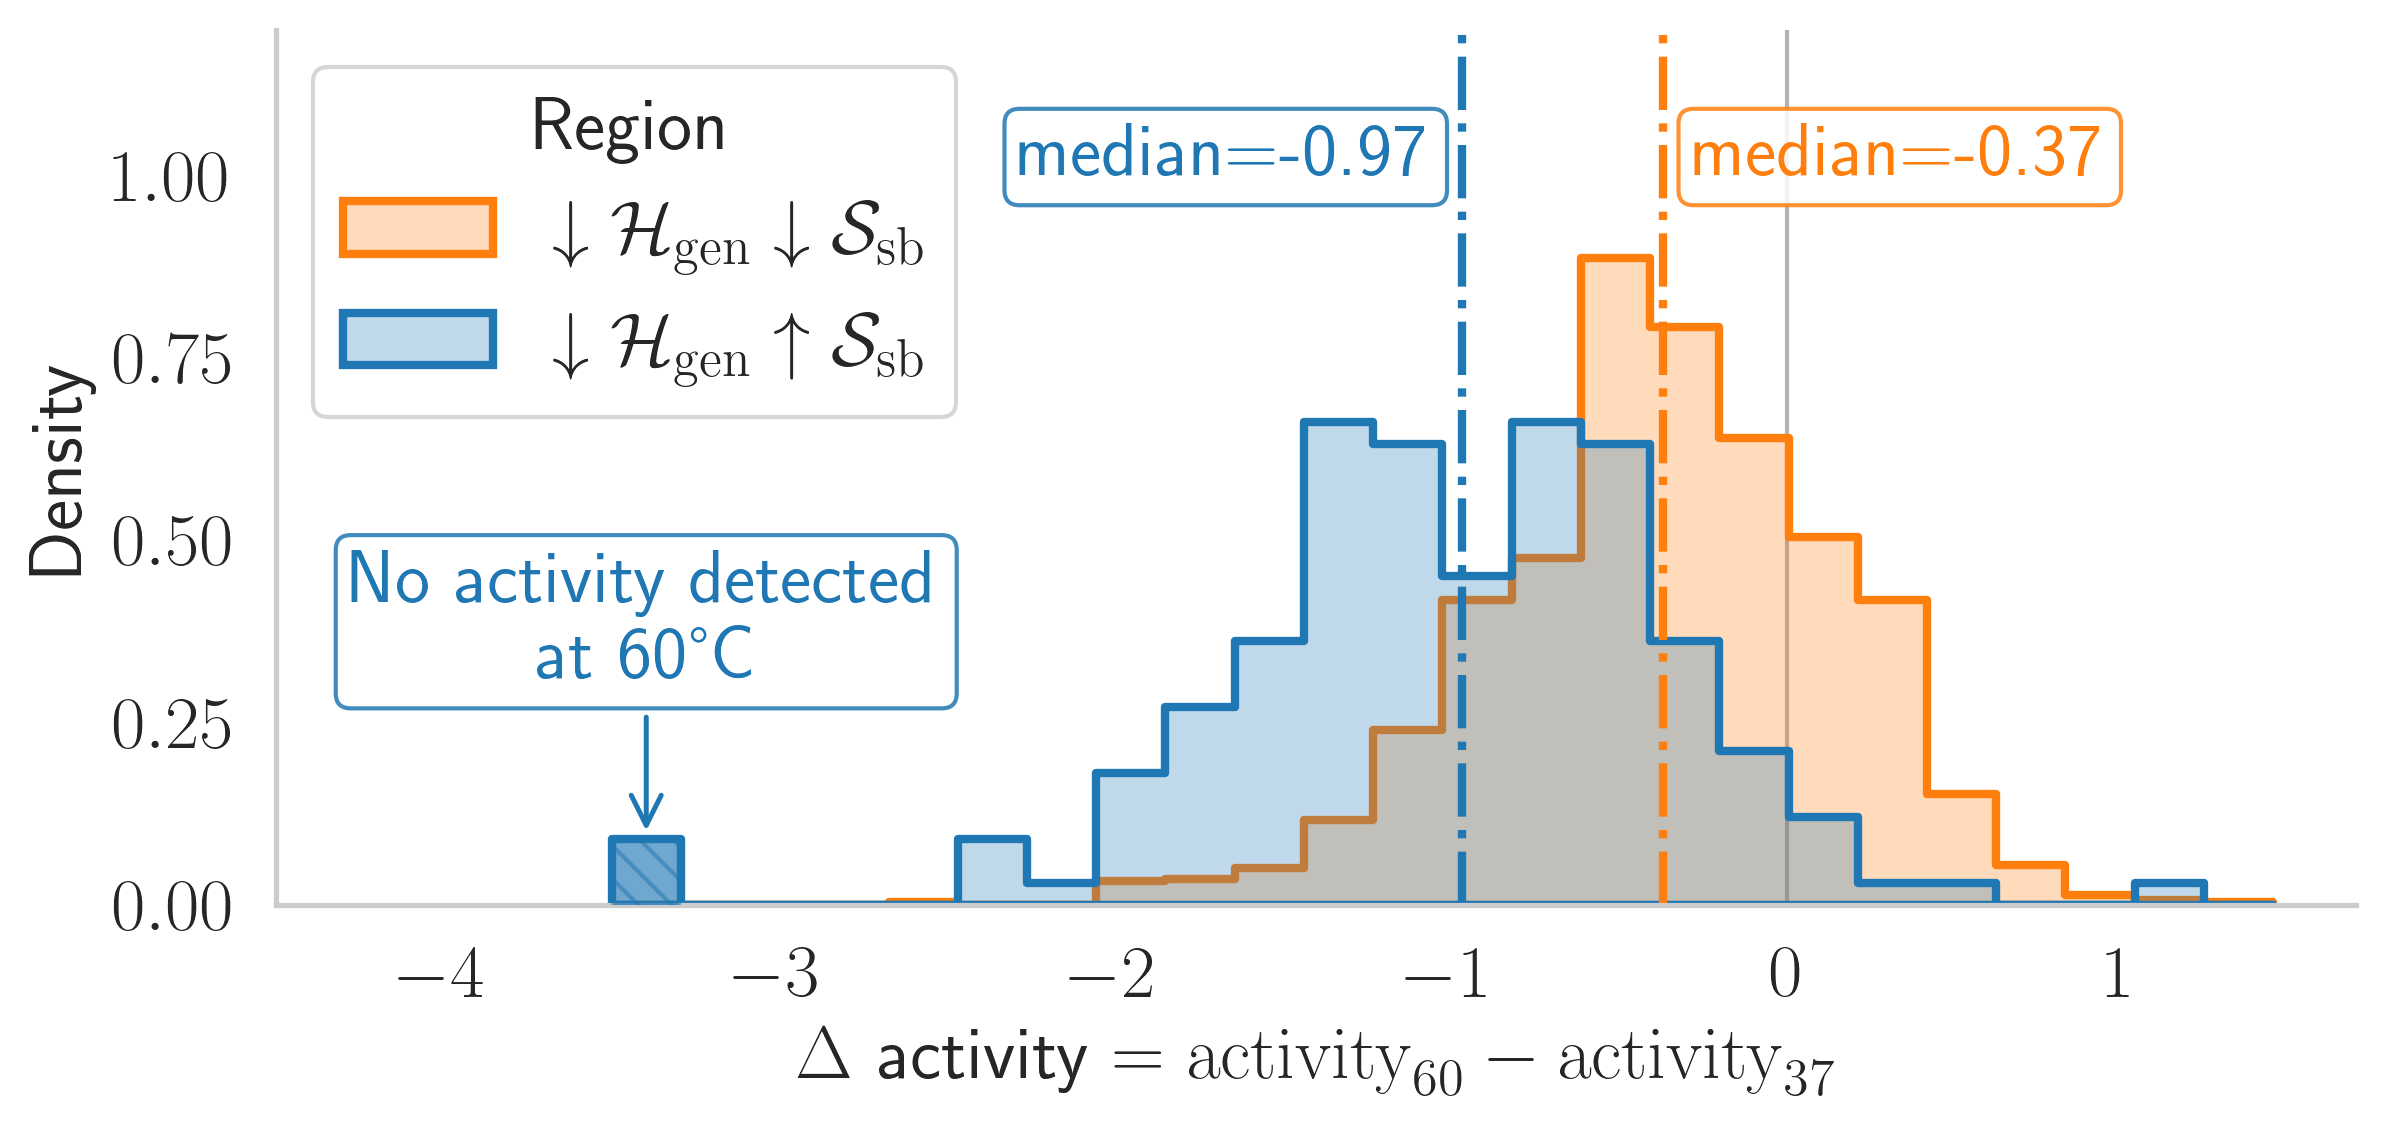

In [102]:
global_font_size = 18
tick_font_size = 18
plt.rcParams.update({"font.size": global_font_size})

# Compare delta-activity distributions by region with highlighted medians
plot_regions = ["lowDCA_highSB", "lowDCA_lowSB"]
plot_df = df_delta[df_delta["region"].isin(plot_regions)].copy()

# --- Custom legend controls ---
# Set to None to use default region names
custom_legend_labels = {
    "lowDCA_highSB": r"$\downarrow \mathcal{H}_\mathrm{gen} \downarrow \mathcal{S}_\mathrm{sb}$",
    "lowDCA_lowSB": r"$\downarrow \mathcal{H}_\mathrm{gen} \uparrow \mathcal{S}_\mathrm{sb}$",
}
legend_title = "Region"
show_counts_in_legend = True

if plot_df.empty:
    print("No sequences satisfy the requested filters.")
else:
    sns.set_theme(style="whitegrid")

    tab10 = sns.color_palette("tab10")
    palette = {
        "lowDCA_highSB": tab10[1],
        "lowDCA_lowSB": tab10[0],
    }

    fig, ax = plt.subplots(figsize=(8, 4), dpi=300)

    # Use common bin edges so overlays are perfectly aligned
    all_vals = plot_df["delta_activity"].dropna().values
    bins = 24
    bin_edges = np.linspace(all_vals.min(), all_vals.max(), bins + 1)

    # overlaid histograms
    for region in plot_regions:
        vals = plot_df.loc[plot_df["region"] == region, "delta_activity"].dropna()
        if len(vals) == 0:
            continue

        legend_name = custom_legend_labels.get(region, region)
        legend_label = f"{legend_name}" if show_counts_in_legend else legend_name

        sns.histplot(
            vals,
            bins=bin_edges,
            stat="density",
            element="step",
            fill=True,
            alpha=0.28,
            linewidth=2.0,
            color=palette[region],
            label=legend_label,
            ax=ax,
        )

        # median line + label
        med = np.median(vals)
        ax.axvline(med, color=palette[region], linestyle="-.", linewidth=2.)
        y_top = ax.get_ylim()[1]
        ax.text(
            med + 0.09 if region == "lowDCA_highSB" else med - 0.09,
            y_top * 1.15,
            f"median={med:.2f}",
            color=palette[region],
            rotation=0,
            va="top",
            ha="left" if region == "lowDCA_highSB" else "right",
            bbox=dict(facecolor="white", edgecolor=palette[region], alpha=0.85, boxstyle="round,pad=0.2"),
            fontsize=global_font_size,
        )

    # Highlight the blue histogram bin around x=-3 with blue hatched fill
    vals_blue = plot_df.loc[plot_df["region"] == "lowDCA_lowSB", "delta_activity"].dropna().values
    if len(vals_blue) > 0:
        hist_blue, _ = np.histogram(vals_blue, bins=bin_edges, density=True)
        idx = np.searchsorted(bin_edges, pos_inactive_60, side="right") - 1
        if 0 <= idx < len(hist_blue) and hist_blue[idx] > 0:
            x_left = bin_edges[idx]
            x_right = bin_edges[idx + 1]
            x_center = (x_left + x_right) / 2
            bar_height = hist_blue[idx]
            ax.bar(
                x=x_center,
                height=bar_height,
                width=(x_right - x_left) * 0.95,
                color=palette["lowDCA_lowSB"],
                edgecolor=palette["lowDCA_lowSB"],
                alpha=0.5,
                hatch="\\\\\\",
                linewidth=1.0,
                zorder=6,
            )

            # Annotation arrow to the hatched bar
            ax.annotate(
                "No activity detected\nat 60°C",
                xy=(x_center, bar_height),
                xytext=(x_center + 0., bar_height + 0.2),
                arrowprops=dict(arrowstyle="->", color=tab10[0], linewidth=1.2),
                ha="center",
                va="bottom",
                fontsize=global_font_size,
                c=tab10[0],
                bbox=dict(facecolor="white", edgecolor=tab10[0], alpha=0.85, boxstyle="round,pad=0.2"),
            )

    ax.axvline(0.0, color="black", linestyle="-", linewidth=1., alpha=0.3, zorder=0)
    ax.set_xlabel(r"$\Delta$ activity $= \mathrm{activity}_{60} - \mathrm{activity}_{37}$", fontsize=global_font_size)
    ax.set_ylabel("Density", fontsize=global_font_size)
    ax.tick_params(axis="both", which="major", labelsize=tick_font_size)
    ax.legend(frameon=True, title=legend_title, fontsize=global_font_size, title_fontsize=global_font_size)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    #ax.grid(True, alpha=0.3, ls="--")
    ax.grid(False)
    ax.set_xlim(-4.5)
    ax.set_ylim(0, 1.2)

    plt.tight_layout()
    plt.savefig("../../../results/Images/Group_I_intron/delta_activities.pdf")
    plt.show()

### Correlation between activity and hydrogen bonds within one region

In [73]:
def h_bond_vector_from_sequences(sequences, dot_bracket_file):
    """
    Read sequences and a consensus structure from a
    dot-bracket file, then return the H-bond count for each sequence.

    GC/CG pairs contribute 3 H-bonds.
    AU/UA/GU/UG pairs contribute 2 H-bonds.
    All other pairs contribute 0.
    """

    def dot_bracket_pairs(structure):
        stack = []
        pairs = []
        for i, char in enumerate(structure):
            if char == '(':
                stack.append(i)
            elif char == ')':
                if not stack:
                    raise ValueError('Invalid dot-bracket structure: too many closing parentheses.')
                pairs.append((stack.pop(), i))
        if stack:
            raise ValueError('Invalid dot-bracket structure: too many opening parentheses.')
        return pairs

    def count_h_bonds(seq, pairs):
        h_bonds = 0
        for i, j in pairs:
            if i >= len(seq) or j >= len(seq):
                continue
            bp = seq[i] + seq[j]
            if bp in ['GC', 'CG']:
                h_bonds += 3
            elif bp in ['AU', 'UA', 'GU', 'UG']:
                h_bonds += 2
        return h_bonds

    with open(dot_bracket_file, 'r') as f:
        structure = ''.join(line.strip() for line in f if line.strip())

    pairs = dot_bracket_pairs(structure)
    return [count_h_bonds(seq, pairs) for seq in sequences]

In [74]:
fname_wts = "../../WTs_to_thermo_fix.fasta"
file_structure = "../Group_I_Intron/dot-bracket-structure.txt"
from adabmDCA import import_from_fasta
wt_names, wt_sequences = import_from_fasta(fname_wts)
h_bonds_wts = h_bond_vector_from_sequences(wt_sequences, file_structure)
for name, hbonds in zip(wt_names, h_bonds_wts):
    print(name, hbonds)

wt_1 124
wt_2 131
wt_3 131
wt_4 132
wt_5 130
wt_6 134
wt_7 127
wt_8 128
wt_9 125
wt_10 127
